# Beamline Optimization - Initialization
This notebook performs sequential optimization of the UH beamline using custom modules and beam parameters.

Help for associated beamline element indexing: image.png

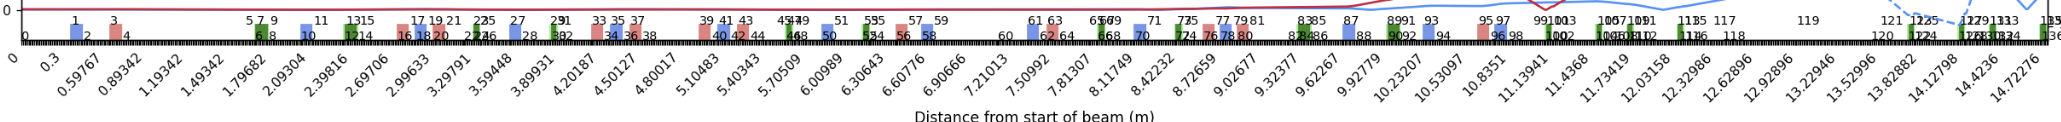

In [ ]:
# Import Python modules
%matplotlib ipympl
import time
import numpy as np
import pandas as pd
import sympy as sp
import sympy.plotting as plot

# Import Beam Dynamics modules
from felsim import paths
from felsim.ebeam import beam
from felsim.beamline import lattice, beamline
from felsim.schematic import draw_beamline
from felsim.excelElements import ExcelElements
from felsim.beamOptimizer import beamOptimizer
from felsim.AlgebraicOptimization import AlgebraicOpti

In [ ]:
from felsim.parameters import chicane_inputs

# Initial Beam Parameters at the chicane entrance (parameters/UH_reference_parameters.yaml)
inputs = chicane_inputs()
Energy = inputs['kinetic_energy_eV'] * 1e-6  # MeV
f = 2856e6  # Hz
bunch_spread = inputs['sigma_t_s'] * 1e12  # ps
energy_std_percent = inputs['energy_spread_rms'] * 1e2  # %
h = 5e9  # 1/s

epsilon_n = inputs['emittance_n_x_m'] * 1e6  # pi.mm.mrad
nb_particles = 100000

relat = lattice(1,fringeType=None)
relat.setE(E=Energy)
norm = relat.gamma * relat.beta
epsilon = epsilon_n / norm
print(relat.gamma)
print(relat.beta)
print(epsilon)
x_std = np.sqrt(epsilon * inputs['beta_x_m'])  # mm, from mm.mrad * m at alpha = 0
y_std = np.sqrt(epsilon * inputs['beta_y_m'])  # mm
x_prime_std = epsilon / x_std
y_prime_std = epsilon / y_std

tof_std = bunch_spread * 1e-9 * f
gen_tof = np.random.normal(0, tof_std, size=(nb_particles, 1))
energy_std = energy_std_percent * 10

ebeam = beam()
beam_dist = ebeam.gen_6d_gaussian(0, [x_std,x_prime_std,y_std,y_prime_std,tof_std,energy_std], nb_particles)
tof_dist = beam_dist[:,4] / f
beam_dist[:,5] += h * tof_dist


# MkV FEL Undulator matching
K = 1.2
lambda_u = 2.3  # Undulator period in cm

beta_ym = relat.gamma / (K * (2 * np.pi / (lambda_u * 1e-2)))
print(beta_ym)
y_std_m = np.sqrt(epsilon * 1e-6 * beta_ym)
print(y_std_m)
y_prime_std_m = np.sqrt(epsilon * 1e-6 / beta_ym) # Beam at waist so Gamma(z_w) = 1 / Beta(z_w)
print(y_prime_std_m)

In [ ]:
# Load Beamline from Excel
path = paths.EXCEL_DIR
file_path = path / 'Beamline_elements.xlsx'
excel = ExcelElements(file_path)
df = excel.get_dataframe()
beamlineUH = excel.create_beamline()
schem = draw_beamline()
line_UH = relat.changeBeamType("electron", Energy, beamlineUH)

# Optimizer and beamline truncation
print('Number of elements in beamline: ' + str(len(line_UH)))
segments = 138
line = line_UH[:segments]
opti = beamOptimizer(line, beam_dist)

In [ ]:
# Optimization - First Quadrupole Doublet

variables = {
    1: ["I", "current", lambda num:num],
    3: ["I2", "current", lambda num:num],
}
startPoint = {
    "I": {"bounds": (0,10), "start": 1},
    "I2": {"bounds": (0, 10), "start": 1},
}

objectives = {8: [{"measure": ["x", "alpha"], "goal": 0, "weight":1},
                  {"measure": ["x", "beta"], "goal": 0.1, "weight":0.0}],
              9: [{"measure": ["y", "alpha"], "goal": 0, "weight":1},
                  {"measure": ["y", "beta"], "goal": 0.1, "weight":0.5}]}            

result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)

# old values
# line[1].current = 0.9989681933
# line[3].current = 1.044851479

In [ ]:
# Optimization - First Chromacity Quad

variables = {10: ["I", "current", lambda num:num]}
startPoint = {"I": {"bounds": (0,10), "start": 1}}
objectives = {15: [{"measure": ["x", "dispersion"], "goal": 0, "weight": 1}]}
result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)

In [ ]:
# Optimization - Quadrupole Triplet

truncated_line = line[:17]
# Add half a quad
#truncated_line.append(qpfLattice(current = 3.816604, length=0.0889/2))

variables = {
    16: ["I", "current", lambda num:num],
    18: ["I2", "current", lambda num:num],
    20: ["I3", "current", lambda num:num],
}
startPoint = {
    "I": {"bounds": (0,10), "start": 2},
    "I2": {"bounds": (0, 10), "start": 5},
    "I3": {"bounds": (0, 10), "start": 3},
}

objectives = {25: [{"measure": ["x", "alpha"], "goal": 0, "weight":1},
                  {"measure": ["x", "beta"], "goal": 0.1, "weight":0.5}],
              26: [{"measure": ["y", "alpha"], "goal": 0, "weight":1},
                  {"measure": ["y", "beta"], "goal": 0.1, "weight":0.5}]}     

result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)

# old values
# line[16].current = 2.4
# line[18].current = 5.108214683
# line[20].current = 3.142089844

In [ ]:
# Optimization - Second Chromacity Quad

variables = {27: ["I", "current", lambda num:num]}
startPoint = {"I": {"bounds": (0,10), "start": 1}}
objectives = {32: [{"measure": ["x", "dispersion"], "goal": 0, "weight": 1}]}
result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)

In [ ]:
# Optimization - Double Quadrupole Triplet

variables = {
    37: ["I", "current", lambda num:num],
    35: ["I2", "current", lambda num:num],
    33: ["I3", "current", lambda num:num],
}
startPoint = {
    "I": {"bounds": (0,10), "start": 2},
    "I2": {"bounds": (0, 10), "start": 2},
    "I3": {"bounds": (0, 10), "start": 2},
}
objectives = {
    37: [
        {"measure": ["x", "alpha"], "goal": 0, "weight": 1},
        {"measure": ["y", "alpha"], "goal": 0, "weight": 1},
        {"measure": ["x", "envelope"], "goal": 2.0, "weight": 1},
        {"measure": ["y", "envelope"], "goal": 2.0, "weight": 1}
    ]
}
result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)

line[43].current = line[33].current
line[41].current = line[35].current
line[39].current = line[37].current

In [ ]:
# Optimization - Third Chromacity Quad

variables = {50: ["I", "current", lambda num:num]}
startPoint = {"I": {"bounds": (0,10), "start": 1}}
objectives = {55: [{"measure": ["x", "dispersion"], "goal": 0, "weight": 1}]}
result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)


In [ ]:
# Optimization - Quadrupole Doublet and Interaction Point (z = 7.11 m, end of element index = 59)

variables = {
    56: ["I", "current", lambda num:num],
    58: ["I2", "current", lambda num:num],
}
startPoint = {
    "I": {"bounds": (0,10), "start": 2},
    "I2": {"bounds": (0, 10), "start": 2},
}

objectives = {
    59: [
        {"measure": ["x", "envelope"], "goal": 0.0, "weight": 1},
        {"measure": ["y", "envelope"], "goal": 0.0, "weight": 1}
    ]
}

result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)

In [ ]:
# Optimization - Quadrupole Doublet

variables = {
    61: ["I", "current", lambda num:num],
    63: ["I2", "current", lambda num:num],
}
startPoint = {
    "I": {"bounds": (0,10), "start": 2},
    "I2": {"bounds": (0, 10), "start": 2},
}

objectives = {
    68: [{"measure": ["x", "alpha"], "goal": 0, "weight": 1},
        {"measure": ["x", "beta"], "goal": 0.1, "weight": 0.5}],
    69: [{"measure": ["y", "alpha"], "goal": 0, "weight": 1},
         {"measure": ["y", "beta"], "goal": 0.1, "weight": 0.5}]
}

result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)


In [ ]:
# Optimization - Fourth Chromacity Quad

variables = {70: ["I", "current", lambda num:num]}
startPoint = {"I": {"bounds": (0,10), "start": 1}}
objectives = {75: [{"measure": ["x", "dispersion"], "goal": 0, "weight": 1}]}
result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)

In [ ]:
# Optimization - Quadrupole Triplet

variables = {
    76: ["I", "current", lambda num:num],
    78: ["I2", "current", lambda num:num],
    80: ["I3", "current", lambda num:num],
}
startPoint = {
    "I": {"bounds": (0,10), "start": 2},
    "I2": {"bounds": (0, 10), "start": 2},
    "I3": {"bounds": (0, 10), "start": 2},
}

objectives = {
    85: [{"measure": ["x", "alpha"], "goal": 0, "weight": 1},
        {"measure": ["x", "beta"], "goal": 0.1, "weight": 0.5}],
    86: [{"measure": ["y", "alpha"], "goal": 0, "weight": 1},
         {"measure": ["y", "beta"], "goal": 0.1, "weight": 0.5}]
}

result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)

In [ ]:
# Optimization - Fifth Chromacity Quad

variables = {87: ["I", "current", lambda num:num]}
startPoint = {"I": {"bounds": (0,10), "start": 1}}
objectives = {92: [{"measure": ["x", "dispersion"], "goal": 0, "weight": 1}]}
result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)

In [ ]:
# Optimization - Quadrupole Triplet and MkIII undulator start (z = 12.389 m , end of element index = 117)

variables = {
    93: ["I", "current", lambda num:num],
    95: ["I2", "current", lambda num:num],
    97: ["I3", "current", lambda num:num],
}
startPoint = {
    "I": {"bounds": (0,10), "start": 2},
    "I2": {"bounds": (0, 10), "start": 2},
    "I3": {"bounds": (0, 10), "start": 2},
}
objectives = {
    117: [
        {"measure": ["x", "alpha"], "goal": 0, "weight": 1},
        {"measure": ["y", "alpha"], "goal": 0, "weight": 1},
        {"measure": ["x", "beta"], "goal": beta_ym, "weight": 1},
        {"measure": ["y", "beta"], "goal": beta_ym, "weight": 1}
    ]
}
result = opti.calc("Nelder-Mead", variables, startPoint, objectives, plotBeam=False, printResults=True, plotProgress=False)


#indice 93 new current value: 2.1275944045328767
#indice 95 new current value: 1.543397467601471
#indice 97 new current value: 0.3798657737076452

In [ ]:
# Display Optimized Beamline

%matplotlib ipympl
acceptance = {"shape":'circle', "radius":1, "origin":[0,0]}
schem.plotBeamPositionTransform(beam_dist, line, 0.01, plot=True, showIndice=False, 
                                defineLim=False, matchScaling=False, shape=acceptance, scatter=True)

